In [7]:
import os
import sys
import json
from pathlib import Path

from ipywidgets import widgets
from ipyfilechooser import FileChooser
from IPython.display import display, clear_output

sys.path.append(os.path.abspath('..'))
from care.l5 import do_data_processing_l5, test_loss_l5, do_training_l5
from care.data_augmentation import apply_data_augmentation_to_npz

In [ ]:
start_dir = os.path.abspath('../../data') if os.path.isdir('../../data') else os.getcwd()
fc_data = FileChooser(start_dir)
fc_data.title = '<b>Select the "Training_L5" folder (Low, High, Mask):</b>'
fc_data.show_only_dirs = True

w_t_low = widgets.IntText(value=3, description='Time window for low images:', style={'description_width': 'initial'})
w_val = widgets.FloatSlider(value=0.1, min=0.05, max=0.15, step=0.01, description='Validation fraction:', style={'description_width': 'initial'})
btn_npz = widgets.Button(description='Generate .npz', button_style='success', icon='play')
out_npz = widgets.Output()

def on_npz_clicked(b):
    global DATASET_DIR, MODELS_ROOT, NPZ_TRAIN, NPZ_VAL, DATASET_INFO
    with out_npz:
        clear_output()
        if fc_data.selected is None:
            print("Error: please select the dataset folder.")
            return
        DATASET_DIR = Path(fc_data.selected)
        MODELS_ROOT = DATASET_DIR.parent / 'models'
        NPZ_TRAIN, NPZ_VAL = do_data_processing_l5(DATASET_DIR, MODELS_ROOT / f"{DATASET_DIR.parent.name}_L5",
                                                   w_t_low.value, w_val.value)
        info_file = DATASET_DIR / 'dataset_info.json'
        DATASET_INFO = json.load(open(info_file)) if info_file.exists() else {}
        print("Mask size:", DATASET_INFO.get('mask_size'), "| detection threshold:", DATASET_INFO.get('threshold'))

btn_npz.on_click(on_npz_clicked)
display(widgets.VBox([fc_data, w_t_low, w_val, btn_npz, out_npz]))

In [9]:
test_loss_l5(w=10, lam=0)
test_loss_l5(w=10, lam=10)

w = 10, lam = 0: extra cost compared with the perfect prediction
  perfect           MAE +  0.00   L5 +   0.00   
  missed molecule   MAE +  1.68   L5 +  18.43   x11.0
  invented spot     MAE +  1.36   L5 +  32.15   x23.6
w = 10, lam = 10: extra cost compared with the perfect prediction
  perfect           MAE +  0.00   L5 +   0.00   
  missed molecule   MAE +  1.68   L5 +  18.43   x11.0
  invented spot     MAE +  1.36   L5 +  62.93   x46.2


In [10]:
w_kernel = widgets.IntText(value=3, description='Kernel Size:')
w_depth = widgets.IntText(value=2, description='Net Depth:')
w_first = widgets.IntText(value=64, description='First Layer:')
w_epochs = widgets.IntText(value=100, description='Epochs:')
w_lr = widgets.FloatText(value=1e-4, description='Learn Rate:', step=1e-5)
w_w = widgets.FloatText(value=10.0, description='w (molecules):')
w_lam = widgets.FloatText(value=0.0, description='λ (invented):')
w_thr = widgets.FloatText(value=DATASET_INFO.get('threshold', 200.0), description='Threshold:')
w_ms = widgets.IntText(value=DATASET_INFO.get('mask_size', 7), description='Mask size:')
w_seed = widgets.IntText(value=0, description='Seed:')

display(widgets.VBox([
    widgets.HTML("<b>Architecture</b>"), widgets.HBox([w_kernel, w_depth, w_first]),
    widgets.HTML("<b>Training</b>"), widgets.HBox([w_epochs, w_lr, w_seed]),
    widgets.HTML("<b>L5 loss</b> (w = 0 and λ = 0: standard MAE)"), widgets.HBox([w_w, w_lam]), widgets.HBox([w_thr, w_ms]),
]))


L5 with w = 0, lam = 0
number of training images:	 9000
number of validation images:	 0
image size (2D):		 (64, 64)
axes:				 SYXC
channels in / out:		 3 / 2
number of training images:	 1000
number of validation images:	 0
image size (2D):		 (64, 64)
axes:				 SYXC
channels in / out:		 3 / 2
Config(n_dim=2, axes='YXC', n_channel_in=3, n_channel_out=1, train_checkpoint='weights_best.h5', train_checkpoint_last='weights_last.h5', train_checkpoint_epoch='weights_now.h5', probabilistic=False, unet_residual=False, unet_n_depth=2, unet_kern_size=3, unet_n_first=64, unet_last_activation='linear', unet_input_shape=(None, None, 3), train_loss='mae', train_epochs=30, train_steps_per_epoch=400, train_learning_rate=0.0001, train_batch_size=16, train_tensorboard=False, train_reduce_lr={'factor': 0.5, 'patience': 10, 'min_delta': 0.0001})
Run info saved in /Users/aneuhaus/Desktop/SCOL/data/SPT/models/L5_w0_lam0_k3d2l64_T3_0002/run_info.json
Epoch 1/30


2026-11-05 16:58:19.052237: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


400/400 [==============================] - ETA: 0s - loss: 206.4238 - mae_img: 206.4238 - mse_img: 100005.0234 - mae_mol: 575.1845 - fp_spots: 0.0000e+00

2026-11-05 16:58:48.128604: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


400/400 [==============================] - 31s 76ms/step - loss: 206.4238 - mae_img: 206.4238 - mse_img: 100005.0234 - mae_mol: 575.1845 - fp_spots: 0.0000e+00 - val_loss: 171.6277 - val_mae_img: 171.5827 - val_mse_img: 57692.5820 - val_mae_mol: 546.4713 - val_fp_spots: 0.0000e+00 - lr: 1.0000e-04
Epoch 2/30
400/400 [==============================] - 31s 78ms/step - loss: 171.7208 - mae_img: 171.7208 - mse_img: 57243.1914 - mae_mol: 527.7297 - fp_spots: 0.0000e+00 - val_loss: 172.5626 - val_mae_img: 172.5318 - val_mse_img: 58221.3750 - val_mae_mol: 544.4832 - val_fp_spots: 0.0000e+00 - lr: 1.0000e-04
Epoch 3/30
400/400 [==============================] - 32s 79ms/step - loss: 170.9740 - mae_img: 170.9740 - mse_img: 55859.6992 - mae_mol: 504.9989 - fp_spots: 0.0000e+00 - val_loss: 169.6633 - val_mae_img: 169.5842 - val_mse_img: 53868.6055 - val_mae_mol: 481.0211 - val_fp_spots: 0.0000e+00 - lr: 1.0000e-04
Epoch 4/30
400/400 [==============================] - 33s 83ms/step - loss: 170.183

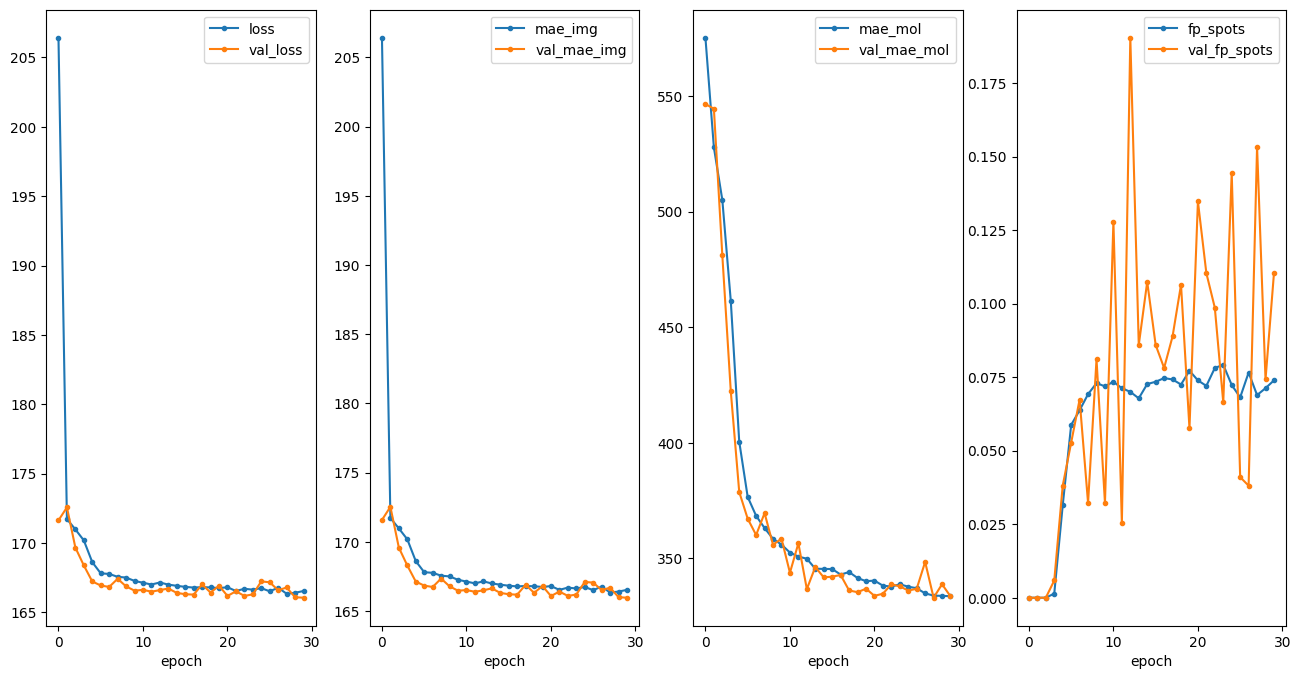


L5 with w = 10, lam = 0
number of training images:	 9000
number of validation images:	 0
image size (2D):		 (64, 64)
axes:				 SYXC
channels in / out:		 3 / 2
number of training images:	 1000
number of validation images:	 0
image size (2D):		 (64, 64)
axes:				 SYXC
channels in / out:		 3 / 2
Config(n_dim=2, axes='YXC', n_channel_in=3, n_channel_out=1, train_checkpoint='weights_best.h5', train_checkpoint_last='weights_last.h5', train_checkpoint_epoch='weights_now.h5', probabilistic=False, unet_residual=False, unet_n_depth=2, unet_kern_size=3, unet_n_first=64, unet_last_activation='linear', unet_input_shape=(None, None, 3), train_loss='mae', train_epochs=30, train_steps_per_epoch=400, train_learning_rate=0.0001, train_batch_size=16, train_tensorboard=False, train_reduce_lr={'factor': 0.5, 'patience': 10, 'min_delta': 0.0001})
Run info saved in /Users/aneuhaus/Desktop/SCOL/data/SPT/models/L5_w10_lam0_k3d2l64_T3_0003/run_info.json
Epoch 1/30


2026-11-05 17:13:48.665476: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


400/400 [==============================] - ETA: 0s - loss: 311.2762 - mae_img: 210.9383 - mse_img: 98830.5703 - mae_mol: 482.4237 - fp_spots: 0.0341

2026-11-05 17:14:18.650840: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


400/400 [==============================] - 32s 78ms/step - loss: 311.2762 - mae_img: 210.9383 - mse_img: 98830.5703 - mae_mol: 482.4237 - fp_spots: 0.0341 - val_loss: 253.8158 - val_mae_img: 171.0280 - val_mse_img: 50954.6211 - val_mae_mol: 392.2230 - val_fp_spots: 0.0410 - lr: 1.0000e-04
Epoch 2/30
400/400 [==============================] - 30s 75ms/step - loss: 254.1747 - mae_img: 171.3146 - mse_img: 50199.3086 - mae_mol: 363.7641 - fp_spots: 0.1930 - val_loss: 251.0086 - val_mae_img: 168.9171 - val_mse_img: 48788.1172 - val_mae_mol: 350.1337 - val_fp_spots: 0.3545 - lr: 1.0000e-04
Epoch 3/30
400/400 [==============================] - 30s 76ms/step - loss: 247.1288 - mae_img: 169.1627 - mse_img: 48634.2617 - mae_mol: 348.3768 - fp_spots: 0.1691 - val_loss: 242.2820 - val_mae_img: 167.3882 - val_mse_img: 47695.7930 - val_mae_mol: 346.4429 - val_fp_spots: 0.0859 - lr: 1.0000e-04
Epoch 4/30
400/400 [==============================] - 30s 74ms/step - loss: 246.4194 - mae_img: 168.9274 - m

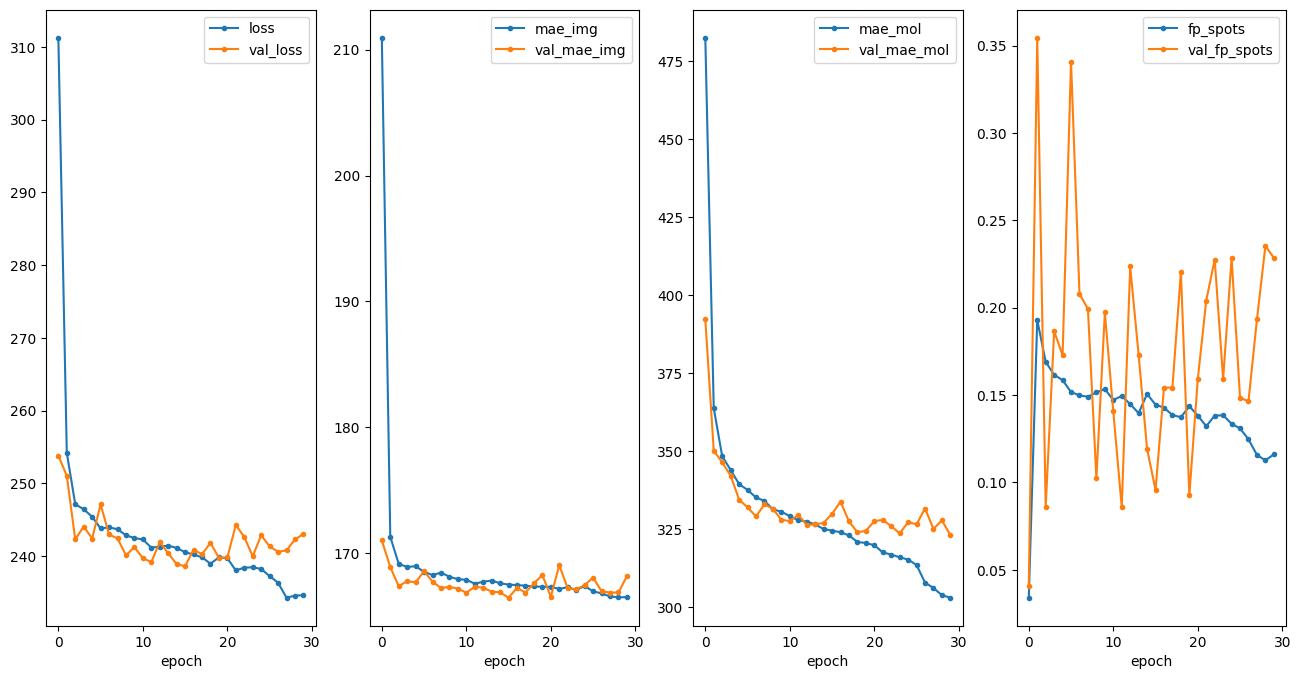


L5 with w = 10, lam = 10
number of training images:	 9000
number of validation images:	 0
image size (2D):		 (64, 64)
axes:				 SYXC
channels in / out:		 3 / 2
number of training images:	 1000
number of validation images:	 0
image size (2D):		 (64, 64)
axes:				 SYXC
channels in / out:		 3 / 2
Config(n_dim=2, axes='YXC', n_channel_in=3, n_channel_out=1, train_checkpoint='weights_best.h5', train_checkpoint_last='weights_last.h5', train_checkpoint_epoch='weights_now.h5', probabilistic=False, unet_residual=False, unet_n_depth=2, unet_kern_size=3, unet_n_first=64, unet_last_activation='linear', unet_input_shape=(None, None, 3), train_loss='mae', train_epochs=30, train_steps_per_epoch=400, train_learning_rate=0.0001, train_batch_size=16, train_tensorboard=False, train_reduce_lr={'factor': 0.5, 'patience': 10, 'min_delta': 0.0001})
Run info saved in /Users/aneuhaus/Desktop/SCOL/data/SPT/models/L5_w10_lam10_k3d2l64_T3_0001/run_info.json
Epoch 1/30


2026-11-05 17:29:01.277682: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


400/400 [==============================] - ETA: 0s - loss: 313.9477 - mae_img: 210.8632 - mse_img: 98872.7578 - mae_mol: 484.2694 - fp_spots: 0.0245

2026-11-05 17:29:31.676782: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


400/400 [==============================] - 33s 79ms/step - loss: 313.9477 - mae_img: 210.8632 - mse_img: 98872.7578 - mae_mol: 484.2694 - fp_spots: 0.0245 - val_loss: 258.3603 - val_mae_img: 170.9989 - val_mse_img: 51133.2109 - val_mae_mol: 398.1299 - val_fp_spots: 0.0273 - lr: 1.0000e-04
Epoch 2/30
400/400 [==============================] - 30s 76ms/step - loss: 260.4061 - mae_img: 171.3151 - mse_img: 50247.6445 - mae_mol: 366.1395 - fp_spots: 0.1369 - val_loss: 260.2818 - val_mae_img: 169.0068 - val_mse_img: 48773.6016 - val_mae_mol: 351.1298 - val_fp_spots: 0.2793 - lr: 1.0000e-04
Epoch 3/30
400/400 [==============================] - 28s 70ms/step - loss: 253.1846 - mae_img: 169.1586 - mse_img: 48677.8359 - mae_mol: 350.8649 - fp_spots: 0.1231 - val_loss: 247.4503 - val_mae_img: 167.4630 - val_mse_img: 47696.0586 - val_mae_mol: 348.9183 - val_fp_spots: 0.0596 - lr: 1.0000e-04
Epoch 4/30
400/400 [==============================] - 29s 73ms/step - loss: 252.4101 - mae_img: 168.8816 - m

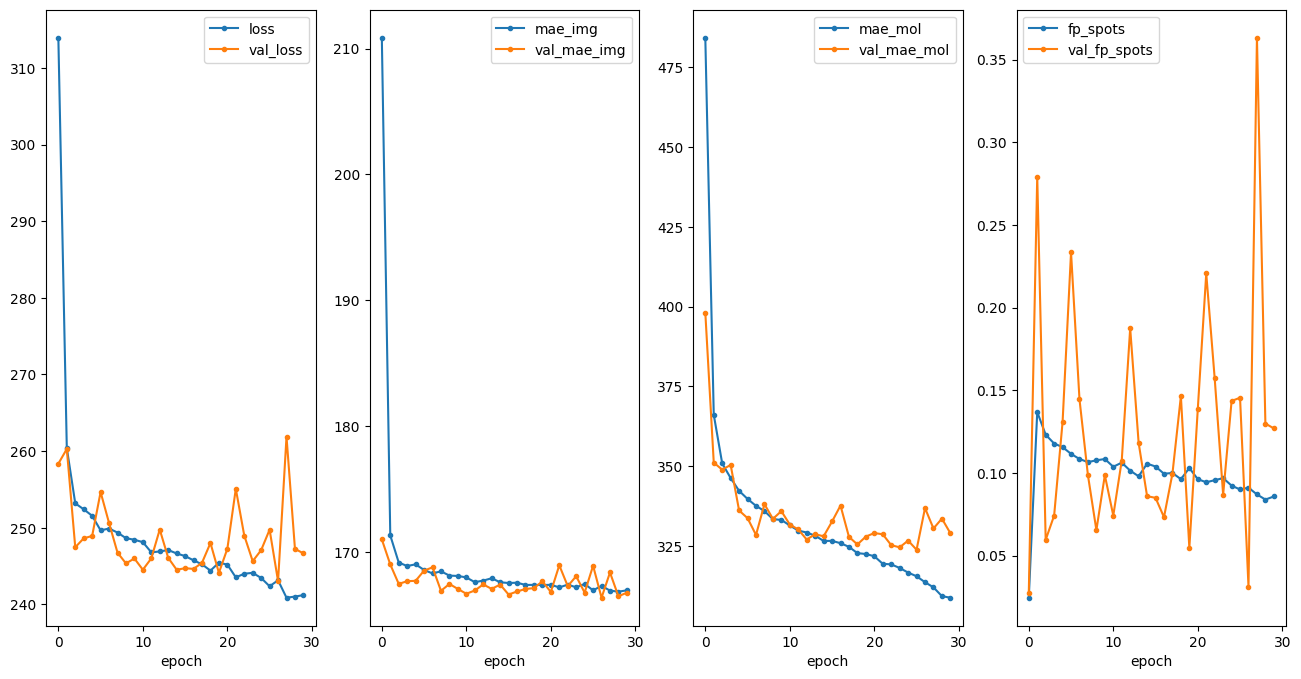

In [11]:
for w, lam in ((0, 0), (10, 0), (10, 10)):
    print(f"\n{'=' * 60}\nL5 with w = {w}, lam = {lam}\n{'=' * 60}")
    do_training_l5(NPZ_TRAIN, NPZ_VAL, MODELS_ROOT,
                   kernel_size=w_kernel.value, unet_depth=w_depth.value, unet_first_layer=w_first.value,
                   train_epochs=30, lr=w_lr.value,
                   w=w, lam=lam, threshold=w_thr.value, mask_size=w_ms.value,
                   seed=w_seed.value, dataset_dir=DATASET_DIR)

In [12]:
import json
import numpy as np
import tensorflow as tf
from scipy import ndimage as ndi
from csbdeep.models import CARE
from csbdeep.io import load_training_data
from care.l5 import _spots, mae_img, mae_mol

(X_val, Y_val), _, _ = load_training_data(NPZ_VAL, validation_split=0, verbose=False)
yt = tf.constant(Y_val)
masks = Y_val[..., 1]

for d in sorted(MODELS_ROOT.glob('L5_*')):
    info = json.load(open(d / 'run_info.json'))
    model = CARE(None, d.name, basedir=str(MODELS_ROOT))          # loads weights_best.h5
    pred = tf.constant(model.keras_model.predict(X_val, batch_size=16, verbose=0))
    spots = _spots(pred, w_thr.value).numpy()[..., 0]
    invented = (spots * (1 - masks)).sum() / len(X_val)
    found = total = 0
    for s, m in zip(spots, masks):
        lab, n = ndi.label(m)
        total += n
        found += len(set(np.unique(lab[s > 0])) - {0})
    print(f"{d.name:36s} ({info['data_train']['n_patches']} patches)  mae_img {float(mae_img(yt, pred)):7.2f}  "
          f"mae_mol {float(mae_mol(yt, pred)):7.2f}  invented/patch {invented:.3f}  molecules found {100 * found / total:.0f} %")

Loading network weights from 'weights_best.h5'.


2026-11-05 17:44:17.362871: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


L5_w0_lam0_k3d2l64_T3_0001           (1800 patches)  mae_img  166.42  mae_mol  348.30  invented/patch 0.073  molecules found 54 %
Loading network weights from 'weights_best.h5'.


2026-11-05 17:44:19.842386: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


L5_w0_lam0_k3d2l64_T3_0002           (9000 patches)  mae_img  166.05  mae_mol  334.28  invented/patch 0.107  molecules found 57 %
Loading network weights from 'weights_best.h5'.


2026-11-05 17:44:21.863400: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


... (3 outputs left out)

2026-11-05 17:44:25.721181: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


L5_w10_lam0_k3d2l64_T3_0003          (9000 patches)  mae_img  166.57  mae_mol  330.79  invented/patch 0.092  molecules found 56 %
Loading network weights from 'weights_best.h5'.


2026-11-05 17:44:27.655168: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


L5_w10_lam10_k3d2l64_T3_0001         (9000 patches)  mae_img  166.46  mae_mol  337.91  invented/patch 0.032  molecules found 51 %
